# U-Net model selection

Compare the ReLU and Tanh U-Nets from `tim-testing.ipynb` across positive-class
weights and model widths. Edit the three search lists below, then run the notebook
from top to bottom. Requires the same PyTorch, NumPy, Pillow, Matplotlib, and tqdm
packages as the source notebook.

Every combination starts with a fresh model, optimizer, scheduler, and random
seed, using the same 85%/15% training/validation split and augmentation. Rank
trials by their **best validation Dice** at a fixed probability threshold of 0.5.
Weighted losses use different objectives across positive weights, so do not use
their values to rank trials. The held-out test set is evaluated only for the winner.


In [6]:
from pathlib import Path
from itertools import product
from datetime import datetime, timezone
import csv
import gc
import json
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from tqdm.auto import tqdm

POSITIVE_WEIGHTS = [5.0, 10.0, 15.0, 20.0, 30.0]
MODEL_SIZES = [16, 24, 32]  # Base channels; encoder widths are c, 2c, 4c, 8c.
ACTIVATIONS = ["relu", "tanh"]

SEED = 42
IMAGE_SIZE = 512  # Must be divisible by 8 for the three pooling stages.
BATCH_SIZE = 2
NUM_WORKERS = 0
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 50
PATIENCE = 10
VALIDATION_FRACTION = 0.15
OUTPUT_ROOT = Path("model_selection_runs")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

assert POSITIVE_WEIGHTS and MODEL_SIZES and ACTIVATIONS, "Search lists cannot be empty."
assert all(math.isfinite(w) and w > 0 for w in POSITIVE_WEIGHTS)
assert all(isinstance(c, int) and not isinstance(c, bool) and c > 0 for c in MODEL_SIZES)
assert all(a in {"relu", "tanh"} for a in ACTIVATIONS)
assert IMAGE_SIZE > 0 and IMAGE_SIZE % 8 == 0
assert BATCH_SIZE > 0 and MAX_EPOCHS > 0 and PATIENCE > 0
assert 0 < VALIDATION_FRACTION < 1

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Helps reproducibility; exact results can still vary across hardware.
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)

seed_everything(SEED)
trial_grid = list(product(POSITIVE_WEIGHTS, MODEL_SIZES, ACTIVATIONS))
print(f"Device: {DEVICE}; mixed precision: {USE_AMP}")
print(f"{len(trial_grid)} trials; at most {len(trial_grid) * MAX_EPOCHS} training epochs")


Device: cuda; mixed precision: True
30 trials; at most 1500 training epochs


## Fixed data split

Use the original image resizing, binary mask threshold, and paired flips.
Only examples from the dataset's `train` directory participate in selection.


In [7]:
# Support both this repository layout and common Colab upload locations.
roots = [Path("MuralDH/Mural_seg"), Path("/content/MuralDH/Mural_seg"), Path("/content/Mural_seg")]
DATA_ROOT = next((root for root in roots if root.exists()), None)
if DATA_ROOT is None:
    raise FileNotFoundError("Mural_seg was not found locally or under /content.")

def paired_paths(split):
    """Match each input PNG to a label PNG with the same filename."""
    image_dir = DATA_ROOT / split / "images"
    label_dir = DATA_ROOT / split / "labels"
    pairs = [(p, label_dir / p.name) for p in sorted(image_dir.glob("*.png"))]
    missing = [mask for _, mask in pairs if not mask.exists()]
    if missing or not pairs:
        raise RuntimeError(f"Invalid {split} pairs: {len(pairs)} images, {len(missing)} missing masks")
    return pairs

class MuralDataset(Dataset):
    """Load RGB images and binary one-channel pixel masks."""
    def __init__(self, pairs, augment=False):
        self.pairs = pairs
        self.augment = augment

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        image_path, mask_path = self.pairs[index]
        with Image.open(image_path) as source:
            image = source.convert("RGB")
        with Image.open(mask_path) as source:
            mask = source.convert("L")

        size = (IMAGE_SIZE, IMAGE_SIZE)
        # Nearest-neighbor preserves mask classes; bilinear is suitable for photos.
        if image.size != size:
            image = image.resize(size, Image.Resampling.BILINEAR)
        if mask.size != size:
            mask = mask.resize(size, Image.Resampling.NEAREST)

        # Image and mask must receive identical geometric augmentation.
        if self.augment and random.random() < 0.5:
            image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            mask = mask.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
        if self.augment and random.random() < 0.5:
            image = image.transpose(Image.Transpose.FLIP_TOP_BOTTOM)
            mask = mask.transpose(Image.Transpose.FLIP_TOP_BOTTOM)

        # Convert HWC uint8 data to PyTorch's CHW float format.
        image = np.asarray(image, dtype=np.float32) / 255.0
        image = torch.from_numpy(image.transpose(2, 0, 1).copy())
        # Explicit thresholding handles the different PNG modes in MuralDH.
        mask = (np.asarray(mask, dtype=np.uint8) > 127).astype(np.float32)
        mask = torch.from_numpy(mask.copy()).unsqueeze(0)
        return image, mask

train_pairs = paired_paths("train")
if len(train_pairs) < 2:
    raise ValueError("At least two training images are required for a train/validation split.")
order = torch.randperm(len(train_pairs), generator=torch.Generator().manual_seed(SEED)).tolist()
validation_count = max(1, min(len(order) - 1, round(VALIDATION_FRACTION * len(order))))
validation_indices, training_indices = order[:validation_count], order[validation_count:]
train_data = Subset(MuralDataset(train_pairs, augment=True), training_indices)
validation_data = Subset(MuralDataset(train_pairs), validation_indices)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                   pin_memory=DEVICE.type == "cuda", persistent_workers=False,
                   worker_init_fn=seed_worker)

def make_loaders():
    # Independent generators keep the shuffle/worker seeds equal across trials.
    train_loader = DataLoader(train_data, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED), **loader_args)
    validation_loader = DataLoader(validation_data, shuffle=False,
                                   generator=torch.Generator().manual_seed(SEED), **loader_args)
    return train_loader, validation_loader

print(f"Train: {len(train_data)}, validation: {len(validation_data)}")


Train: 646, validation: 114


## Original ReLU and Tanh architectures

`MODEL_SIZES` controls the base channel count, keeping depth, batch normalization,
transpose convolutions, skip connections, and linear one-channel output unchanged.
A width of 32 reproduces the original baseline. Tanh changes only hidden activations;
the loss still receives raw logits.


In [8]:
class DoubleConv(nn.Module):
    """Two convolution-normalization-activation stages."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.layers(x)

class UNet(nn.Module):
    """Compact three-level U-Net producing one logit per image pixel."""
    def __init__(self, channels=32, block=DoubleConv):
        super().__init__()
        c = channels
        self.pool = nn.MaxPool2d(2)
        # Supplying a different block lets us compare activations without
        # changing the U-Net's channel counts, skip connections, or output shape.
        self.enc1, self.enc2 = block(3, c), block(c, 2*c)
        self.enc3, self.bridge = block(2*c, 4*c), block(4*c, 8*c)
        self.up3 = nn.ConvTranspose2d(8*c, 4*c, 2, 2)
        self.dec3 = block(8*c, 4*c)
        self.up2 = nn.ConvTranspose2d(4*c, 2*c, 2, 2)
        self.dec2 = block(4*c, 2*c)
        self.up1 = nn.ConvTranspose2d(2*c, c, 2, 2)
        self.dec1 = block(2*c, c)
        self.output = nn.Conv2d(c, 1, 1)

    def forward(self, x):
        skip1 = self.enc1(x)
        skip2 = self.enc2(self.pool(skip1))
        skip3 = self.enc3(self.pool(skip2))
        x = self.bridge(self.pool(skip3))
        x = self.dec3(torch.cat([self.up3(x), skip3], dim=1))
        x = self.dec2(torch.cat([self.up2(x), skip2], dim=1))
        x = self.dec1(torch.cat([self.up1(x), skip1], dim=1))
        return self.output(x)  # Raw logits; loss applies sigmoid internally.


class TanhDoubleConv(nn.Module):
    """The same double-convolution block, using Tanh instead of ReLU."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.Tanh(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.Tanh(),
        )

    def forward(self, x):
        return self.layers(x)


BLOCKS = {"relu": DoubleConv, "tanh": TanhDoubleConv}


## Shared loss and pixel metrics

Keep the original 50/50 weighted BCE and soft Dice loss. Pass each trial's
positive weight explicitly to prevent one trial from changing another's loss.
Dice, IoU, precision, and recall aggregate pixel counts across the entire split.


In [9]:
def segmentation_loss(logits, targets, positive_weight):
    """Weighted BCE handles imbalance; Dice directly rewards overlap."""
    weight = logits.new_tensor([positive_weight])
    bce = F.binary_cross_entropy_with_logits(logits, targets, pos_weight=weight)
    probabilities = torch.sigmoid(logits)
    intersection = (probabilities * targets).sum((1, 2, 3))
    total = probabilities.sum((1, 2, 3)) + targets.sum((1, 2, 3))
    dice_loss = 1 - ((2 * intersection + 1) / (total + 1)).mean()
    return 0.5 * bce + 0.5 * dice_loss

def run_epoch(loader, network, positive_weight, optimizer=None, scaler=None):
    """Train when an optimizer is supplied; otherwise only evaluate."""
    training = optimizer is not None
    network.train(training)
    loss_sum = intersection = predicted = actual = 0.0
    for images, targets in tqdm(loader, leave=False):
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = network(images)
                loss = segmentation_loss(logits, targets, positive_weight)
            if training:
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        loss_sum += loss.item() * len(images)
        prediction = torch.sigmoid(logits.detach()) >= 0.5
        target = targets >= 0.5
        intersection += (prediction & target).sum().item()
        predicted += prediction.sum().item(); actual += target.sum().item()
    # Aggregate across the dataset so nearly empty masks do not dominate.
    dice = (2 * intersection + 1e-7) / (predicted + actual + 1e-7)
    iou = (intersection + 1e-7) / (predicted + actual - intersection + 1e-7)
    # Derive precision and recall from pixel-level confusion-matrix counts.
    # Precision = TP / (TP + FP); recall = TP / (TP + FN).
    true_positives = intersection
    false_positives = predicted - intersection
    false_negatives = actual - intersection
    precision_denominator = true_positives + false_positives
    recall_denominator = true_positives + false_negatives
    precision = true_positives / precision_denominator if precision_denominator > 0 else 0.0
    recall = true_positives / recall_denominator if recall_denominator > 0 else 0.0
    return {"loss": loss_sum / len(loader.dataset), "dice": dice, "iou": iou,
            "precision": precision, "recall": recall}


## Train the search grid

Each execution creates a separate output directory; existing source checkpoints
are untouched. Save the split and settings, a CSV leaderboard after each completed
trial, and each trial's best checkpoint plus epoch history. An interrupted search
retains completed trials; rerunning this cell starts a new search, rather than resuming.
Larger widths may require a smaller `BATCH_SIZE` to fit GPU memory.


In [10]:
def train_trial(positive_weight, channels, activation, trial_dir):
    seed_everything(SEED)
    train_loader, validation_loader = make_loaders()
    network = UNet(channels=channels, block=BLOCKS[activation]).to(DEVICE)
    parameter_count = sum(p.numel() for p in network.parameters())
    optimizer = torch.optim.AdamW(network.parameters(), lr=LEARNING_RATE,
                                 weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", patience=2)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    config = dict(positive_weight=float(positive_weight), channels=channels, activation=activation)
    checkpoint_path = trial_dir / "best.pt"
    history = []
    best_dice, stale_epochs = -1.0, 0
    best_metrics, best_epoch = None, None
    started = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        train_metrics = run_epoch(train_loader, network, positive_weight, optimizer, scaler)
        val_metrics = run_epoch(validation_loader, network, positive_weight)
        if not all(math.isfinite(v) for v in (*train_metrics.values(), *val_metrics.values())):
            raise RuntimeError(f"Non-finite metrics in {trial_dir.name}, epoch {epoch}")
        scheduler.step(val_metrics["dice"])
        history.append({"epoch": epoch,
                        **{f"train_{k}": v for k, v in train_metrics.items()},
                        **{f"val_{k}": v for k, v in val_metrics.items()}})
        (trial_dir / "history.json").write_text(json.dumps(history, indent=2))
        print(f"{epoch:02d} | train loss {train_metrics['loss']:.4f} | "
              f"val Dice {val_metrics['dice']:.4f} | IoU {val_metrics['iou']:.4f}")

        if val_metrics["dice"] > best_dice:
            best_dice, stale_epochs = val_metrics["dice"], 0
            best_metrics, best_epoch = val_metrics.copy(), epoch
            torch.save({"model": network.state_dict(), "config": config,
                        "epoch": epoch, "validation_metrics": best_metrics}, checkpoint_path)
        else:
            stale_epochs += 1
            if stale_epochs >= PATIENCE:
                print("Early stopping: validation Dice stopped improving.")
                break

    result = {"trial": trial_dir.name, **config, "parameters": parameter_count,
              "best_epoch": best_epoch, "epochs_trained": len(history),
              **{f"val_{k}": v for k, v in best_metrics.items()},
              "seconds": time.perf_counter() - started, "checkpoint": str(checkpoint_path)}
    (trial_dir / "result.json").write_text(json.dumps(result, indent=2))
    # Return only scalar results, so models/optimizers do not accumulate on the GPU.
    return result


def save_leaderboard(results, destination):
    ranked = sorted(results, key=lambda row: row["val_dice"], reverse=True)
    with destination.open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(ranked[0]))
        writer.writeheader()
        writer.writerows(ranked)
    return ranked


# Rebuild the grid so edits to the lists are reflected when rerunning this cell.
trial_grid = list(product(POSITIVE_WEIGHTS, MODEL_SIZES, ACTIVATIONS))
search_dir = OUTPUT_ROOT / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
search_dir.mkdir(parents=True, exist_ok=False)
settings = dict(positive_weights=POSITIVE_WEIGHTS, model_sizes=MODEL_SIZES,
                activations=ACTIVATIONS, seed=SEED, image_size=IMAGE_SIZE,
                batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE,
                weight_decay=WEIGHT_DECAY, max_epochs=MAX_EPOCHS, patience=PATIENCE,
                validation_fraction=VALIDATION_FRACTION, threshold=0.5,
                device=str(DEVICE), use_amp=USE_AMP, torch_version=str(torch.__version__),
                data_root=str(DATA_ROOT.resolve()))
(search_dir / "settings.json").write_text(json.dumps(settings, indent=2))
(search_dir / "split.json").write_text(json.dumps({
    "training_images": [str(train_pairs[i][0]) for i in training_indices],
    "validation_images": [str(train_pairs[i][0]) for i in validation_indices],
}, indent=2))
results = []
print(f"Saving {len(trial_grid)} trials to {search_dir.resolve()}")
for trial_number, (positive_weight, channels, activation) in enumerate(trial_grid, 1):
    trial_dir = search_dir / f"{trial_number:03d}_{activation}_c{channels}_pw{positive_weight:g}"
    trial_dir.mkdir()
    print(f"\nTrial {trial_number}/{len(trial_grid)}: {trial_dir.name}")
    result = train_trial(positive_weight, channels, activation, trial_dir)
    results.append(result)
    leaderboard = save_leaderboard(results, search_dir / "leaderboard.csv")
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

best_result = leaderboard[0]
(search_dir / "selected_model.json").write_text(json.dumps(best_result, indent=2))
print("\nSelected by validation Dice:", best_result)


Saving 30 trials to /home/timothy-m/Coding/csc-4667-F26/Final-Project/model_selection_runs/20261126T052120_904536Z

Trial 1/30: 001_relu_c16_pw5


01 | train loss 0.7501 | val Dice 0.0000 | IoU 0.0000


02 | train loss 0.7197 | val Dice 0.0002 | IoU 0.0001


03 | train loss 0.7176 | val Dice 0.0000 | IoU 0.0000


04 | train loss 0.7139 | val Dice 0.0000 | IoU 0.0000


05 | train loss 0.7163 | val Dice 0.0000 | IoU 0.0000


... (698 outputs left out)

20 | train loss 1.1247 | val Dice 0.0918 | IoU 0.0481


21 | train loss 1.1183 | val Dice 0.0909 | IoU 0.0476


22 | train loss 1.1179 | val Dice 0.0916 | IoU 0.0480


23 | train loss 1.1238 | val Dice 0.0902 | IoU 0.0472
Early stopping: validation Dice stopped improving.

Selected by validation Dice: {'trial': '009_relu_c24_pw10', 'positive_weight': 10.0, 'channels': 24, 'activation': 'relu', 'parameters': 1084681, 'best_epoch': 40, 'epochs_trained': 50, 'val_loss': 0.8373473621251291, 'val_dice': 0.14450380236088287, 'val_iou': 0.07787879196129127, 'val_precision': 0.09729040147028493, 'val_recall': 0.28074430942192663, 'seconds': 1224.8827907329996, 'checkpoint': 'model_selection_runs/20261126T052120_904536Z/009_relu_c24_pw10/best.pt'}


## Compare validation results

All reported validation metrics come from the epoch selected by validation Dice
for that trial. CSV, JSON, and checkpoints are saved under `search_dir`.
The final graph compares both activations at every positive weight/model size pair.


In [11]:
print(f"{'Rank':>4} {'Activation':>10} {'Channels':>8} {'Pos weight':>10} "
      f"{'Params':>10} {'Epoch':>6} {'Dice':>8} {'IoU':>8} {'Prec.':>8} {'Recall':>8}")
for rank, row in enumerate(leaderboard, 1):
    print(f"{rank:4d} {row['activation']:>10} {row['channels']:8d} "
          f"{row['positive_weight']:10g} {row['parameters']:10,d} {row['best_epoch']:6d} "
          f"{row['val_dice']:8.4f} {row['val_iou']:8.4f} "
          f"{row['val_precision']:8.4f} {row['val_recall']:8.4f}")


Rank Activation Channels Pos weight     Params  Epoch     Dice      IoU    Prec.   Recall
   1       relu       24         10  1,084,681     40   0.1445   0.0779   0.0973   0.2807
   2       relu       24         15  1,084,681     19   0.1424   0.0767   0.0865   0.4026
   3       relu       16         10    482,737     22   0.1411   0.0759   0.0961   0.2649
   4       relu       32         15  1,927,009     18   0.1399   0.0752   0.0834   0.4349
   5       relu       32         10  1,927,009     22   0.1385   0.0744   0.0949   0.2563
   6       relu       16         15    482,737     19   0.1344   0.0720   0.0787   0.4594
   7       relu       16         20    482,737     20   0.1228   0.0654   0.0699   0.5052
   8       relu       16         30    482,737     10   0.1207   0.0642   0.0756   0.2990
   9       relu       32         20  1,927,009     20   0.1192   0.0634   0.0671   0.5317
  10       relu       24          5  1,084,681     32   0.1165   0.0619   0.1484   0.0960
  11      

## Evaluate the selected model on the held-out test set

Run this after finishing model selection. Load the winning validation checkpoint
and evaluate it with its own positive weight. Avoid choosing hyperparameters from
the test metrics; use the validation leaderboard for that decision.


In [12]:
checkpoint = torch.load(best_result["checkpoint"], map_location="cpu", weights_only=False)
selected_config = checkpoint["config"]
selected_model = UNet(channels=selected_config["channels"],
                      block=BLOCKS[selected_config["activation"]])
selected_model.load_state_dict(checkpoint["model"])
selected_model = selected_model.to(DEVICE)
del checkpoint

test_data = MuralDataset(paired_paths("test"))
test_loader = DataLoader(test_data, shuffle=False, **loader_args)
test_metrics = run_epoch(test_loader, selected_model, selected_config["positive_weight"])
(search_dir / "test_metrics.json").write_text(json.dumps({
    "selected_config": selected_config, "checkpoint": best_result["checkpoint"],
    "test_metrics": test_metrics,
}, indent=2))
print("Selected configuration:", selected_config)
print("Test metrics:", {key: round(value, 4) for key, value in test_metrics.items()})


Selected configuration: {'positive_weight': 10.0, 'channels': 24, 'activation': 'relu'}
Test metrics: {'loss': 0.9146, 'dice': 0.1512, 'iou': 0.0818, 'precision': 0.117, 'recall': 0.2134}


## All models: split-circle Dice comparison

Each location represents a positive weight (x) and model size in base channels (y).
The **left blue half-circle is ReLU**; the **right orange half-circle is Tanh**.
Each half-circle's **diameter is directly proportional to best validation Dice**,
using the same scale for both activations and all trials. Thus a Dice of 0.8 has
twice the diameter of 0.4; area is not proportional to Dice. A zero score has zero
diameter, and a missing activation has no half-circle. Small gray crosses mark the
actual evaluated locations. The graph uses validation scores from every trial;
held-out test scores remain reserved for the selected model.


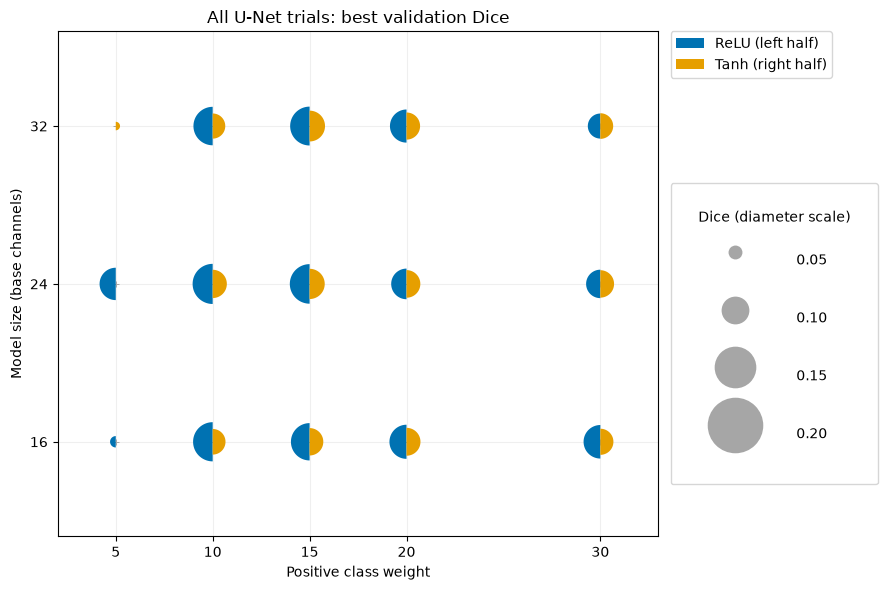

In [18]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.path import Path as MarkerPath

# Same diameter scale for both halves. Lower this if using a very dense grid.
MAX_DIAMETER_POINTS = 200  # Diameter at Dice = 1, in display points.
ACTIVATION_COLORS = {"relu": "#0072B2", "tanh": "#E69F00"}


def half_circle_marker(side):
    # Marker coordinates keep both halves centered at the same grid location.
    angles = np.linspace(np.pi / 2, 3 * np.pi / 2, 101)
    vertices = np.column_stack((np.cos(angles), np.sin(angles)))
    if side == "right":
        vertices[:, 0] *= -1
    vertices = np.vstack((vertices, vertices[0]))
    codes = [MarkerPath.MOVETO] + [MarkerPath.LINETO] * 100 + [MarkerPath.CLOSEPOLY]
    return MarkerPath(vertices, codes)


weights = sorted({row["positive_weight"] for row in results})
sizes = sorted({row["channels"] for row in results})
fig, ax = plt.subplots(figsize=(max(9, 1.4 * len(weights)), max(6, 1.2 * len(sizes))))
ax.set(xlabel="Positive class weight", ylabel="Model size (base channels)",
       title="All U-Net trials: best validation Dice")
ax.set_xticks(weights)
ax.set_yticks(sizes)
x_padding = min(np.diff(weights)) * 0.6 if len(weights) > 1 else max(abs(weights[0]) * 0.25, 1)
y_padding = min(np.diff(sizes)) * 0.6 if len(sizes) > 1 else max(sizes[0] * 0.25, 1)
ax.set_xlim(weights[0] - x_padding, weights[-1] + x_padding)
ax.set_ylim(sizes[0] - y_padding, sizes[-1] + y_padding)
ax.set_axisbelow(True)
ax.grid(alpha=0.2)

locations = sorted({(row["positive_weight"], row["channels"]) for row in results})
ax.scatter(*zip(*locations), marker="+", s=18, color="0.65", linewidths=0.7, zorder=2)
for activation, side in [("relu", "left"), ("tanh", "right")]:
    rows = [row for row in results if row["activation"] == activation]
    if not rows:
        continue
    dice = np.array([row["val_dice"] for row in rows])
    # scatter's s scales area: squaring Dice makes DIAMETER linear in Dice.
    ax.scatter([row["positive_weight"] for row in rows],
               [row["channels"] for row in rows],
               s=(MAX_DIAMETER_POINTS * dice) ** 2,
               marker=half_circle_marker(side), color=ACTIVATION_COLORS[activation],
               edgecolors="none", linewidths=0, alpha=1, zorder=3)

activation_legend = ax.legend(handles=[
    Patch(facecolor=ACTIVATION_COLORS["relu"], label="ReLU (left half)"),
    Patch(facecolor=ACTIVATION_COLORS["tanh"], label="Tanh (right half)"),
], loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
ax.add_artist(activation_legend)
# Full circles show the common diameter scale of the two half-circle markers.
ax.legend(handles=[
    Line2D([], [], linestyle="none", marker="o", color="0.65",
           markeredgewidth=0, markersize=MAX_DIAMETER_POINTS * score,
           label=f"{score:.2f}")
    for score in [0.05, 0.1, 0.15, 0.2]
], title="Dice (diameter scale)", loc="upper left", bbox_to_anchor=(1.02, 0.7),
   borderaxespad=0, handleheight=4.5, labelspacing=1, borderpad=2, handletextpad=3.4)
plt.tight_layout()
fig.savefig(search_dir / "all_models_split_dice.png", dpi=200, bbox_inches="tight")
fig.savefig(search_dir / "all_models_split_dice.svg", bbox_inches="tight")
plt.show()
